# Credit Score Classification – Final Projet

In [37]:
%pip install -q numpy pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
import os, re, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
warnings.filterwarnings("ignore")

%matplotlib inline
DATA = "."; OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

TARGET = "Credit_Score"; LABELS = ["Poor", "Standard", "Good"]  # ordinal: 0,1,2

## 1. Load data

In [39]:
train = pd.read_csv(f"{DATA}/train.csv", low_memory=False)
test = pd.read_csv(f"{DATA}/test.csv", low_memory=False)
train["is_train"], test["is_train"] = 1, 0
df = pd.concat([train, test], ignore_index=True)   # clean both with identical rules
print(train.shape, test.shape)

(100000, 29) (50000, 28)


In [40]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,is_train
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good,1
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good,1
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good,1
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good,1
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good,1


 analysis


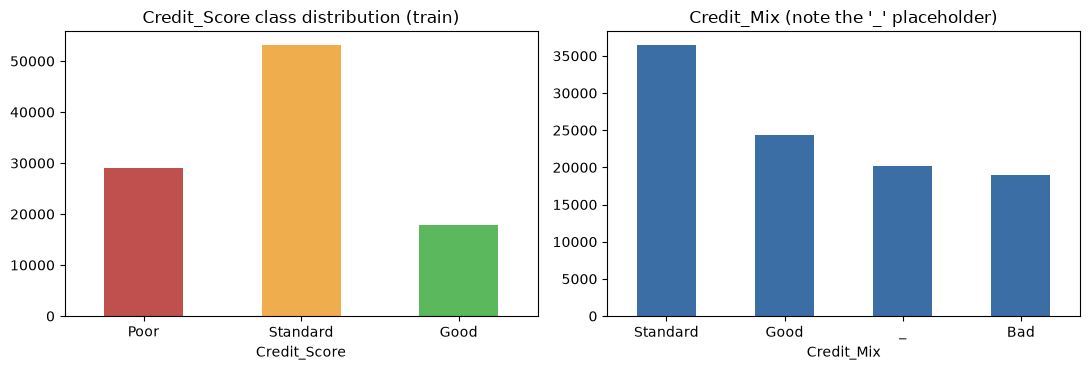

In [70]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
train[TARGET].value_counts().reindex(LABELS).plot.bar(ax=ax[0], color=["#c0504d", "#f0ad4e", "#5cb85c"], rot=0)
ax[0].set_title("Credit_Score class distribution (train)")
train["Credit_Mix"].value_counts().plot.bar(ax=ax[1], rot=0, color="#3b6ea5")
ax[1].set_title("Credit_Mix (note the '_' placeholder)")
plt.tight_layout(); plt.show()

In [71]:
print("Missing values per column (train):")
print(train.isna().sum()[train.isna().sum() > 0])

Missing values per column (train):
Name                        9985
Monthly_Inhand_Salary      15002
Type_of_Loan               11408
Num_of_Delayed_Payment      7002
Num_Credit_Inquiries        1965
Credit_History_Age          9030
Amount_invested_monthly     4479
Monthly_Balance             1200
dtype: int64


In [72]:
print("Examples of dirty Age values:")
print(train["Age"].astype(str)[~train["Age"].astype(str).str.fullmatch(r"\d+")].unique()[:6])

Examples of dirty Age values:
<StringArray>
['-500', '28_', '34_', '30_', '24_', '33_']
Length: 6, dtype: str


In [73]:
print("Payment_Behaviour junk:", (train["Payment_Behaviour"] == "!@9#%8").sum(), "rows")
print("Occupation junk:", (train["Occupation"] == "_______").sum(), "rows")

Payment_Behaviour junk: 7600 rows
Occupation junk: 7062 rows


## 2. Data cleaning

In [42]:
JUNK = ["_", "_______", "!@9#%8", "#F%$D@*&8", "NM", "nan", ""]
for c in df.select_dtypes("object").columns.union(df.select_dtypes("string").columns):
    if c in (TARGET,): continue
    df[c] = df[c].astype(str).str.strip().replace(JUNK, np.nan)

In [43]:
num_like = ["Age","Annual_Income","Num_of_Loan","Num_of_Delayed_Payment","Changed_Credit_Limit",
            "Outstanding_Debt","Amount_invested_monthly","Monthly_Balance"]
for c in num_like:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace("_", "", regex=False), errors="coerce")


In [44]:
def hist_to_months(s):
    if pd.isna(s): return np.nan
    m = re.match(r"(\d+) Years and (\d+) Months", str(s))
    return int(m[1])*12 + int(m[2]) if m else np.nan


In [45]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,is_train
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good,1
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,809.98,31.944960,NaN,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good,1
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521,Low_spent_Medium_value_payments,331.209863,Good,1
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.458074,Low_spent_Small_value_payments,223.451310,Good,1
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153,High_spent_Medium_value_payments,341.489231,Good,1


In [46]:
df["Credit_History_Months"] = df["Credit_History_Age"].map(hist_to_months)


In [47]:
print(df["Age"].dtype) 

int64


In [ ]:
for c in ["Age", "Annual_Income", "Num_of_Loan", "Num_of_Delayed_Payment",
          "Changed_Credit_Limit", "Outstanding_Debt", "Amount_invested_monthly", "Monthly_Balance",
          "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate", "Num_Credit_Inquiries",
          "Total_EMI_per_month", "Delay_from_due_date"]:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace("_", "", regex=False), errors="coerce")

In [49]:
df.loc[~df["Age"].between(14, 100), "Age"] = np.nan


In [50]:
df.loc[(df["Num_of_Loan"] < 0) | (df["Num_of_Loan"] > 20), "Num_of_Loan"] = np.nan
df.loc[(df["Num_Bank_Accounts"] < 0) | (df["Num_Bank_Accounts"] > 20), "Num_Bank_Accounts"] = np.nan


In [51]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,is_train,Credit_History_Months
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,26.822620,22 Years and 1 Months,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good,1,265.0
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,NaN,3.0,...,31.944960,NaN,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good,1,NaN
2,0x1604,CUS_0xd40,March,Aaron Maashoh,NaN,821-00-0265,Scientist,19114.12,NaN,3.0,...,28.609352,22 Years and 3 Months,No,49.574949,81.699521,Low_spent_Medium_value_payments,331.209863,Good,1,267.0
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,NaN,3.0,...,31.377862,22 Years and 4 Months,No,49.574949,199.458074,Low_spent_Small_value_payments,223.451310,Good,1,268.0
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,24.797347,22 Years and 5 Months,No,49.574949,41.420153,High_spent_Medium_value_payments,341.489231,Good,1,269.0


In [52]:
df.loc[df["Num_Credit_Card"] > 20, "Num_Credit_Card"] = np.nan
df.loc[df["Interest_Rate"] > 50, "Interest_Rate"] = np.nan


In [53]:
df.loc[df["Num_of_Delayed_Payment"] < 0, "Num_of_Delayed_Payment"] = np.nan
df.loc[df["Num_of_Delayed_Payment"] > 40, "Num_of_Delayed_Payment"] = np.nan
df.loc[df["Num_Credit_Inquiries"] > 50, "Num_Credit_Inquiries"] = np.nan
df.loc[df["Total_EMI_per_month"] > 2000, "Total_EMI_per_month"] = np.nan
df.loc[df["Amount_invested_monthly"] > 2000, "Amount_invested_monthly"] = np.nan
df.loc[df["Monthly_Balance"] < -1000, "Monthly_Balance"] = np.nan   # e.g. -3333333333
df.loc[df["Monthly_Balance"] > 5000, "Monthly_Balance"] = np.nan

In [54]:
g = df.groupby("Customer_ID")

def cust_mode(s):
    m = s.mode()
    return m.iloc[0] if len(m) else np.nan

In [55]:

static_cols = ["Age","Occupation","Annual_Income","Num_Bank_Accounts",
               "Num_Credit_Card","Interest_Rate","Num_of_Loan","Type_of_Loan"]
for c in static_cols:
    df[c] = df[c].fillna(g[c].transform(cust_mode))

In [56]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,is_train,Credit_History_Months
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,26.822620,22 Years and 1 Months,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good,1,265.0
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,NaN,3.0,...,31.944960,NaN,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good,1,NaN
2,0x1604,CUS_0xd40,March,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,NaN,3.0,...,28.609352,22 Years and 3 Months,No,49.574949,81.699521,Low_spent_Medium_value_payments,331.209863,Good,1,267.0
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,NaN,3.0,...,31.377862,22 Years and 4 Months,No,49.574949,199.458074,Low_spent_Small_value_payments,223.451310,Good,1,268.0
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,24.797347,22 Years and 5 Months,No,49.574949,41.420153,High_spent_Medium_value_payments,341.489231,Good,1,269.0


In [57]:
df["Type_of_Loan"] = df["Type_of_Loan"].fillna("No Loan")

In [58]:
dynamic_cols = ["Monthly_Inhand_Salary","Num_of_Delayed_Payment","Changed_Credit_Limit",
                "Num_Credit_Inquiries","Outstanding_Debt","Credit_Utilization_Ratio",
                "Total_EMI_per_month","Amount_invested_monthly","Monthly_Balance",
                "Delay_from_due_date"]
for c in dynamic_cols:
    df[c] = df[c].fillna(g[c].transform("median"))

In [59]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,is_train,Credit_History_Months
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,26.822620,22 Years and 1 Months,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good,1,265.0
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,31.944960,NaN,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good,1,NaN
2,0x1604,CUS_0xd40,March,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,28.609352,22 Years and 3 Months,No,49.574949,81.699521,Low_spent_Medium_value_payments,331.209863,Good,1,267.0
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,31.377862,22 Years and 4 Months,No,49.574949,199.458074,Low_spent_Small_value_payments,223.451310,Good,1,268.0
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23.0,821-00-0265,Scientist,19114.12,1824.843333,3.0,...,24.797347,22 Years and 5 Months,No,49.574949,41.420153,High_spent_Medium_value_payments,341.489231,Good,1,269.0


In [60]:
month_order = ["January","February","March","April","May","June","July",
               "August","September","October","November","December"]
df["Month_Num"] = df["Month"].map({m: i+1 for i, m in enumerate(month_order)})
df = df.sort_values(["Customer_ID","Month_Num"]).reset_index(drop=True)


In [61]:
df["Credit_History_Months"] = df.groupby("Customer_ID")["Credit_History_Months"].transform(
    lambda s: s.interpolate(limit_direction="both"))


In [62]:
for c in ["Credit_Mix","Payment_of_Min_Amount","Payment_Behaviour"]:
    df[c] = df[c].fillna(df.groupby("Customer_ID")[c].transform(cust_mode))
    df[c] = df[c].fillna("Unknown")
df["Occupation"] = df["Occupation"].fillna("Unknown")


In [63]:
for c in df.select_dtypes("number").columns:
    if c != "is_train":
        df[c] = df[c].fillna(df[c].median())

In [87]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Occ_Entrepreneur,Occ_Journalist,Occ_Lawyer,Occ_Manager,Occ_Mechanic,Occ_Media_Manager,Occ_Musician,Occ_Scientist,Occ_Teacher,Occ_Writer
0,0x1628a,CUS_0x1000,January,Alistair Barrf,17.0,913-74-1218,Lawyer,30625.94,2706.161667,6.0,...,0,0,1,0,0,0,0,0,0,0
1,0x1628b,CUS_0x1000,February,NaN,17.0,913-74-1218,Lawyer,30625.94,2706.161667,6.0,...,0,0,1,0,0,0,0,0,0,0
2,0x1628c,CUS_0x1000,March,Alistair Barrf,17.0,913-74-1218,Lawyer,30625.94,2706.161667,6.0,...,0,0,1,0,0,0,0,0,0,0
3,0x1628d,CUS_0x1000,April,Alistair Barrf,17.0,913-74-1218,Lawyer,30625.94,2706.161667,6.0,...,0,0,1,0,0,0,0,0,0,0
4,0x1628e,CUS_0x1000,May,Alistair Barrf,17.0,913-74-1218,Lawyer,30625.94,2706.161667,6.0,...,0,0,1,0,0,0,0,0,0,0


## 3. Feature engineering

In [64]:
LOAN_TYPES = ["Auto Loan","Credit-Builder Loan","Debt Consolidation Loan","Home Equity Loan",
              "Mortgage Loan","Not Specified","Payday Loan","Personal Loan","Student Loan"]
for lt in LOAN_TYPES:
    df["Loan_" + lt.replace(" ", "_").replace("-", "_")] = df["Type_of_Loan"].str.contains(lt, regex=False).astype(int)

In [65]:
df["Debt_to_Income"]    = df["Outstanding_Debt"] / (df["Annual_Income"] + 1)
df["EMI_to_Salary"]     = df["Total_EMI_per_month"] / (df["Monthly_Inhand_Salary"] + 1)
df["Balance_to_Salary"] = df["Monthly_Balance"] / (df["Monthly_Inhand_Salary"] + 1)
df["Invest_to_Salary"]  = df["Amount_invested_monthly"] / (df["Monthly_Inhand_Salary"] + 1)
df["Cards_per_Account"] = df["Num_Credit_Card"] / (df["Num_Bank_Accounts"] + 1)

In [66]:
df["Credit_Mix_ord"] = df["Credit_Mix"].map({"Bad": 0, "Standard": 1, "Good": 2}).fillna(1)
df["MinPay_ord"]     = df["Payment_of_Min_Amount"].map({"No": 0, "Yes": 1}).fillna(0.5)

pb = df["Payment_Behaviour"]
df["Spend_High"] = pb.str.startswith("High").astype(int)
df["Pay_Size"]   = pb.str.extract(r"_(Small|Medium|Large)_")[0].map({"Small": 0, "Medium": 1, "Large": 2}).fillna(1)

In [67]:
occ = pd.get_dummies(df["Occupation"], prefix="Occ", dtype=int)
df = pd.concat([df, occ], axis=1)

In [68]:
drop = ["ID","Customer_ID","Name","SSN","Month","Type_of_Loan","Credit_History_Age","Credit_Mix",
        "Payment_of_Min_Amount","Payment_Behaviour","Occupation"]
feat_df = df.drop(columns=drop)
trn = feat_df[feat_df.is_train == 1].copy()
tst = feat_df[feat_df.is_train == 0].copy()
groups = df.loc[trn.index, "Customer_ID"].values   # kept only for grouped cross-validation

In [69]:
y = trn[TARGET].map({l: i for i, l in enumerate(LABELS)}).values
FEATS = [c for c in feat_df.columns if c not in (TARGET, "is_train")]
X, Xtest = trn[FEATS], tst[FEATS]
print("features:", len(FEATS), "| train rows:", len(X), "| NaNs left:", int(X.isna().sum().sum()))

features: 51 | train rows: 100000 | NaNs left: 0


In [74]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=300, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=30, min_samples_leaf=5, max_depth=14,
                                            max_features="sqrt", class_weight="balanced", n_jobs=-1, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=150, learning_rate=0.12, max_leaf_nodes=48,
                                                             class_weight="balanced", l2_regularization=1.0, random_state=42),
}

In [75]:
gkf = GroupKFold(n_splits=5)      # grouped by customer so nobody appears in both train and validation
cv_pred = {}                      # out-of-fold predictions per model
scores = {}                       # (accuracy, macro-F1) per model

def evaluate_model(name):
    m = models[name]
    pred = np.zeros(len(y), dtype=int)
    for tr_i, va_i in gkf.split(X, y, groups):
        m.fit(X.iloc[tr_i], y[tr_i])
        pred[va_i] = m.predict(X.iloc[va_i])
    cv_pred[name] = pred
    scores[name] = (accuracy_score(y, pred), f1_score(y, pred, average="macro"))
    print(f"{name:24s} acc={scores[name][0]:.4f}  macroF1={scores[name][1]:.4f}")

In [76]:
evaluate_model("Logistic Regression")

Logistic Regression      acc=0.6571  macroF1=0.6507


In [77]:
evaluate_model("Random Forest")

Random Forest            acc=0.6844  macroF1=0.6794


In [78]:
evaluate_model("Hist Gradient Boosting")

Hist Gradient Boosting   acc=0.6920  macroF1=0.6824


In [79]:
res = pd.DataFrame([(n, a, f) for n, (a, f) in scores.items()],
                   columns=["Model", "Accuracy", "Macro_F1"]).sort_values("Macro_F1", ascending=False)
res.to_csv(f"{OUT}/model_comparison.csv", index=False)
best = res.iloc[0]["Model"]
display(res)
print("Best:", best)

,Model,Accuracy,Macro_F1
2,Hist Gradient Boosting,0.69197,0.682365
1,Random Forest,0.68437,0.679378
0,Logistic Regression,0.65712,0.650705


Best: Hist Gradient Boosting


In [80]:
p = cv_pred[best]
print(classification_report(y, p, target_names=LABELS, digits=3))

              precision    recall  f1-score   support

        Poor      0.670     0.720     0.694     28998
    Standard      0.801     0.646     0.715     53174
        Good      0.538     0.782     0.637     17828

    accuracy                          0.692    100000
   macro avg      0.670     0.716     0.682    100000
weighted avg      0.716     0.692     0.695    100000



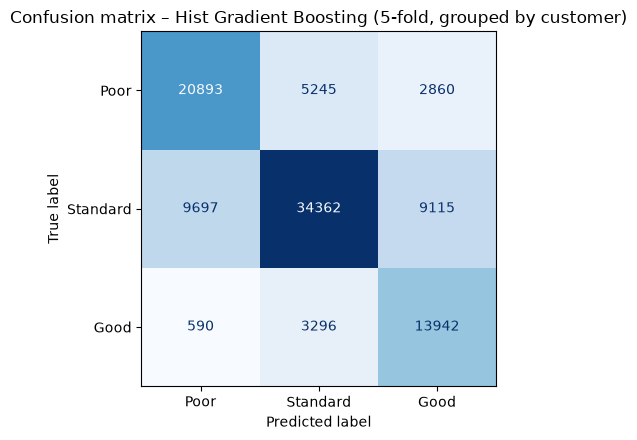

In [81]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y, p), display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix – {best} (5-fold, grouped by customer)")
plt.tight_layout()
plt.savefig(f"{OUT}/confusion_matrix.png", dpi=150)
plt.show()

In [82]:
final = models[best]
final.fit(X, y)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.12
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",150
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",48
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form `{class_label: weight}`.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas `n_samples / (n_classes * np.bincount(y))`.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if `sample_weight` is specified... versionadded:: 1.2",'balanced'
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [83]:
# one grouped split: train on 4/5 of the customers, measure importance on the unseen 1/5
tr_i, va_i = next(GroupKFold(n_splits=5).split(X, y, groups))
imp_model = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.12, max_leaf_nodes=48,
                                           class_weight="balanced", l2_regularization=1.0,
                                           random_state=42).fit(X.iloc[tr_i], y[tr_i])
pi = permutation_importance(imp_model, X.iloc[va_i], y[va_i], n_repeats=3,
                            random_state=0, scoring="f1_macro", n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values(ascending=False)

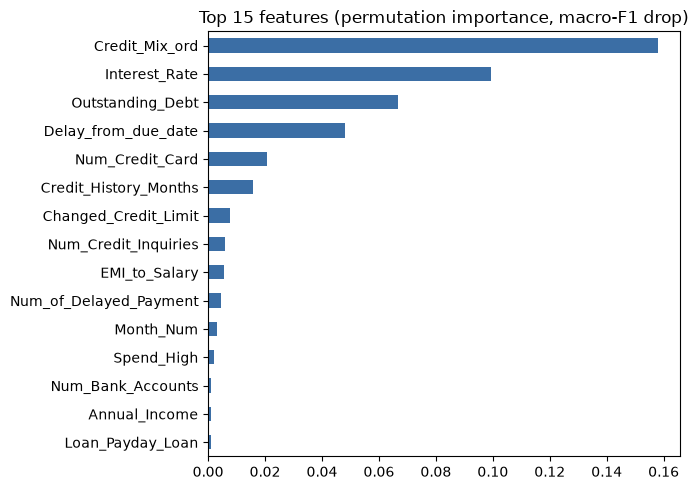

Credit_Mix_ord            0.157847
Interest_Rate             0.099336
Outstanding_Debt          0.066671
Delay_from_due_date       0.047983
Num_Credit_Card           0.020826
Credit_History_Months     0.015855
Changed_Credit_Limit      0.007618
Num_Credit_Inquiries      0.005996
EMI_to_Salary             0.005668
Num_of_Delayed_Payment    0.004592
Month_Num                 0.003295
Spend_High                0.002079
Num_Bank_Accounts         0.001028
Annual_Income             0.001015
Loan_Payday_Loan          0.000940
dtype: float64


In [84]:
imp.head(15).iloc[::-1].plot.barh(figsize=(7, 5), color="#3b6ea5")
plt.title("Top 15 features (permutation importance, macro-F1 drop)")
plt.tight_layout()
plt.savefig(f"{OUT}/feature_importance.png", dpi=150)
plt.show()
print(imp.head(15))

In [85]:
pred_test = final.predict(Xtest)
sub = pd.DataFrame({"ID": df.loc[tst.index, "ID"].values,
                    "Customer_ID": df.loc[tst.index, "Customer_ID"].values,
                    "Predicted_Credit_Score": [LABELS[i] for i in pred_test]})
sub = sub.set_index("ID").loc[test["ID"]].reset_index()   # restore the original test order

In [86]:
sub.to_csv(f"{OUT}/test_predictions.csv", index=False)
print(sub.shape)
print(sub["Predicted_Credit_Score"].value_counts(normalize=True))
sub.head()

(50000, 3)
Predicted_Credit_Score
Standard    0.39812
Poor        0.33570
Good        0.26618
Name: proportion, dtype: float64


,ID,Customer_ID,Predicted_Credit_Score
0,0x160a,CUS_0xd40,Good
1,0x160b,CUS_0xd40,Good
2,0x160c,CUS_0xd40,Good
3,0x160d,CUS_0xd40,Good
4,0x1616,CUS_0x21b1,Good
